# 03. Quanvolutional Neural Networks (QuanvNN) for Medical Imaging
### Quantum Image Filtering with Random Entangling Circuits on BreastMNIST

---

## Overview & Scientific Background
**Quanvolutional Neural Networks (QuanvNN)**, introduced by Henderson et al. (2020), extend classical Convolutional Neural Networks (CNNs) by replacing classical linear kernel filters with **local parameterized quantum circuits**.

### Why Quanvolution?
- **High-Dimensional Hilbert Space Mapping**: A small $2 \times 2$ pixel patch is transformed into the $2^4 = 16$-dimensional state space of 4 entangled qubits.
- **Non-Linear Quantum Kernel Representation**: Quantum gates induce complex non-linear correlations that classical single-layer convolutions cannot natively compute.
- **Scalability for NISQ Devices**: Instead of loading the entire image into a massive quantum register (which requires hundreds of error-corrected qubits), quanvolution operates locally on small patches using only 4 qubits!

---

## 1. Architectural Pipeline

### 1.1 Local Receptive Field & Angle Encoding
For each $2 \times 2$ spatial receptive field $[x_{0,0}, x_{0,1}, x_{1,0}, x_{1,1}]$ with stride $s=2$:
1. **Angle Embedding**: Each normalized pixel intensity $p_j \in [0, 1]$ is encoded into the rotation angle of an $R_Y$ gate:
   $$|\psi_{\text{in}}\rangle = \bigotimes_{j=0}^{3} R_Y(\pi p_j) |0\rangle$$
2. **Entangling Unitary Transformation (`RandomLayers`)**:
   A parameterized unitary transformation $U(\vec{\theta})$ comprising random single-qubit rotations and entangling gates (e.g. CNOTs) mixes the spatial information:
   $$|\psi_{\text{out}}\rangle = U(\vec{\theta}) |\psi_{\text{in}}\rangle$$
3. **Quantum Measurement Observables**:
   Expectation values of the Pauli-$Z$ operator on each of the 4 qubits are extracted:
   $$f_c = \langle \psi_{\text{out}} | \hat{Z}_c | \psi_{\text{out}} \rangle \in [-1, 1], \quad c \in \{0, 1, 2, 3\}$$
4. **Spatial Downsampling**:
   An input image of shape $(28, 28, 1)$ is transformed into a rich 4-channel quantum feature map of shape $(14, 14, 4)$.

### 1.2 Downstream Classification
The extracted quantum feature map is flattened and passed to a Dense classification layer in Keras/TensorFlow for binary medical diagnosis on **BreastMNIST** (benign vs. malignant ultrasound scans).


In [ ]:
!pip install medmnist pennylane tensorflow

In [ ]:
import pennylane as qml
from pennylane import numpy as np
from pennylane.templates import RandomLayers
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import medmnist
from medmnist import BreastMNIST

In [ ]:
n_epochs = 5   # Number of optimization epochs
n_layers = 1    # Number of random layers
n_train = 50    # Size of the train dataset
n_test = 30     # Size of the test dataset

SAVE_PATH = "qcnn_organamnist_"  # Data saving folder/prefix
PREPROCESS = True                # If False, skip quantum processing and load data from SAVE_PATH
np.random.seed(0)
tf.random.set_seed(0)

## 2. Medical Dataset: BreastMNIST
The **BreastMNIST** dataset from the MedMNIST benchmark comprises 2D ultrasound breast cancer images classified as benign (class 0) or malignant (class 1).


In [ ]:
# Downloads automatically to ~/.medmnist on first run
train_dataset = BreastMNIST(split="train", download=True)
test_dataset = BreastMNIST(split="test", download=True)

# .imgs is (N, 28, 28) uint8, .labels is (N, 1)
train_images = train_dataset.imgs[:n_train].astype(np.float64)
train_labels = train_dataset.labels[:n_train].flatten()
test_images = test_dataset.imgs[:n_test].astype(np.float64)
test_labels = test_dataset.labels[:n_test].flatten()

print(train_images.shape, train_labels.shape)
print(test_images.shape, test_labels.shape)

(50, 28, 28) (50,)
(30, 28, 28) (30,)


In [ ]:
# Normalize pixel values within 0 and 1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Add extra dimension for convolution channels -> (N, 28, 28, 1)
# OrganAMNIST is natively grayscale, so we don't need RGB channel averaging
train_images = np.array(train_images[..., tf.newaxis], requires_grad=False)
test_images = np.array(test_images[..., tf.newaxis], requires_grad=False)

## 3. Quantum Convolution Circuit Definition
We configure a 4-qubit PennyLane circuit initialized with $R_Y(\pi \cdot x)$ angle embedding, followed by a random entangling layer (`RandomLayers`) and Pauli-$Z$ expectation measurements.


In [ ]:
dev = qml.device("default.qubit", wires=4)
rand_params = np.random.uniform(high=2 * np.pi, size=(n_layers, 4))

@qml.qnode(dev)
def circuit(phi):
    for j in range(4):
        qml.RY(np.pi * phi[j], wires=j)
    RandomLayers(rand_params, wires=list(range(4)))
    return [qml.expval(qml.PauliZ(j)) for j in range(4)]

In [ ]:
def quanv(image):
    """Convolves the input image with many applications of the same quantum circuit."""
    out = np.zeros((14, 14, 4))
    for j in range(0, 28, 2):
        for k in range(0, 28, 2):
            q_results = circuit(
                [
                    image[j, k, 0],
                    image[j, k + 1, 0],
                    image[j + 1, k, 0],
                    image[j + 1, k + 1, 0]
                ]
            )
            for c in range(4):
                out[j // 2, k // 2, c] = q_results[c].item()
    return out

## 4. Quantum Preprocessing & Feature Extraction
We slide the 4-qubit quanvolutional kernel across all images in the training and testing sets, saving the resulting feature tensors.


In [ ]:
if PREPROCESS:
    q_train_images = []
    print("Quantum pre-processing of train images:")
    for idx, img in enumerate(train_images):
        print(f"{idx + 1}/{n_train}        ", end="\r")
        q_train_images.append(quanv(img))
    q_train_images = np.asarray(q_train_images)

    q_test_images = []
    print("\nQuantum pre-processing of test images:")
    for idx, img in enumerate(test_images):
        print(f"{idx + 1}/{n_test}        ", end="\r")
        q_test_images.append(quanv(img))
    q_test_images = np.asarray(q_test_images)

    np.save(SAVE_PATH + "q_train_images.npy", q_train_images)
    np.save(SAVE_PATH + "q_test_images.npy", q_test_images)
    print("\nPreprocessing complete and saved.")
else:
    q_train_images = np.load(SAVE_PATH + "q_train_images.npy")
    q_test_images = np.load(SAVE_PATH + "q_test_images.npy")
    print("Loaded pre-processed images from disk.")

Quantum pre-processing of train images:

Quantum pre-processing of test images:

Preprocessing complete and saved.


## 5. Visualizing Extracted Quantum Feature Channels
Here we compare the raw grayscale input images with the 4 extracted quantum channel representations.


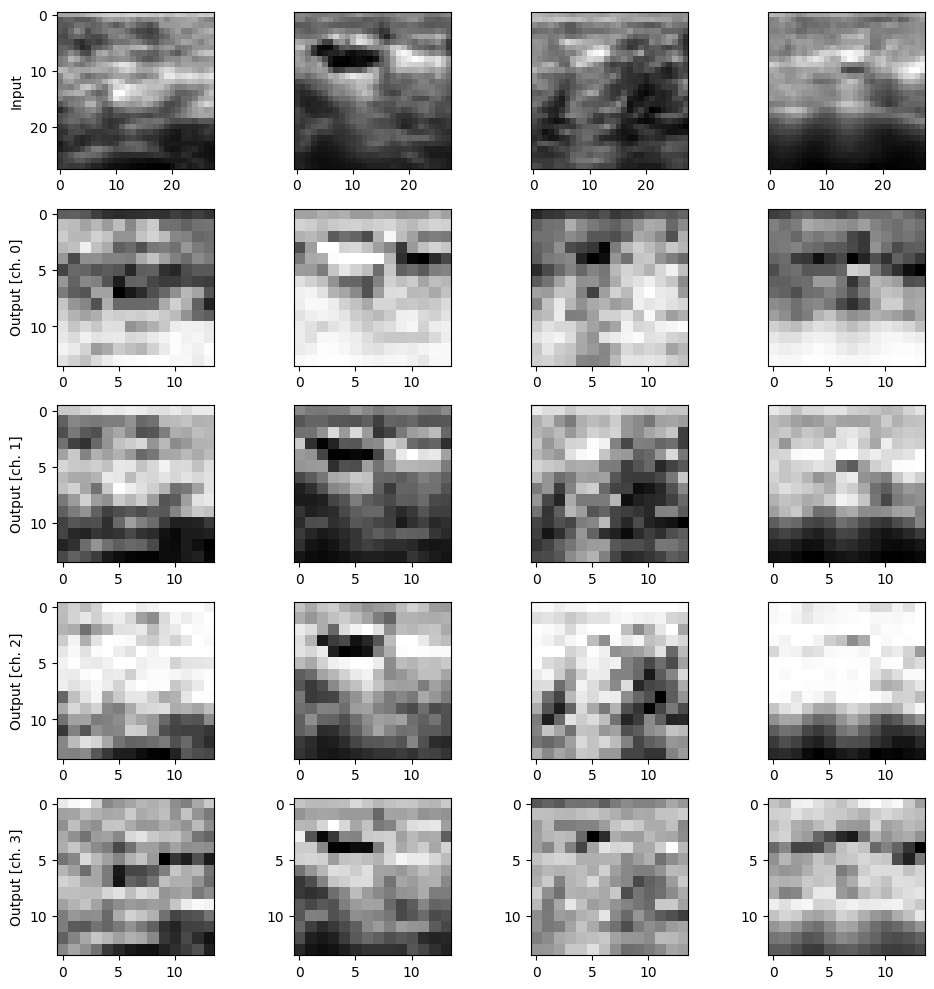

In [ ]:
n_samples = 4
n_channels = 4
fig, axes = plt.subplots(1 + n_channels, n_samples, figsize=(10, 10))
for k in range(n_samples):
    axes[0, 0].set_ylabel("Input")
    if k != 0:
        axes[0, k].yaxis.set_visible(False)
    axes[0, k].imshow(train_images[k, :, :, 0], cmap="gray")

    for c in range(n_channels):
        axes[c + 1, 0].set_ylabel("Output [ch. {}]".format(c))
        if k != 0:
            axes[c, k].yaxis.set_visible(False)
        axes[c + 1, k].imshow(q_train_images[k, :, :, c], cmap="gray")

plt.tight_layout()
plt.show()

## 6. Downstream Model & Comparative Benchmark
We define a classification network in Keras and train two models:
1. **With Quantum Layer**: Trained on the $(14, 14, 4)$ quanvolved feature representations.
2. **Without Quantum Layer**: Trained directly on the raw image pixels as a classical baseline.


In [ ]:
def MyModel():
    """Initializes and returns a custom Keras model which is ready to be trained."""
    model = keras.models.Sequential([
        keras.layers.Flatten(),
        keras.layers.Dense(11, activation="softmax") # Kept at 8 units for TissueMNIST classes
    ])

    model.compile(
        optimizer='adam',
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [ ]:
q_model = MyModel()

# Convert labels to TensorFlow tensors explicitly
train_labels_tf = tf.convert_to_tensor(train_labels, dtype=tf.int32)
test_labels_tf = tf.convert_to_tensor(test_labels, dtype=tf.int32)

q_history = q_model.fit(
    q_train_images,
    train_labels_tf,
    validation_data=(q_test_images, test_labels_tf),
    batch_size=4,
    epochs=n_epochs,
    verbose=2,
)

Epoch 1/5
13/13 - 3s - 238ms/step - accuracy: 0.7000 - loss: 0.9950 - val_accuracy: 0.6667 - val_loss: 0.7489
Epoch 2/5
13/13 - 1s - 45ms/step - accuracy: 0.8400 - loss: 0.4091 - val_accuracy: 0.7000 - val_loss: 0.5731
Epoch 3/5
13/13 - 0s - 21ms/step - accuracy: 0.9000 - loss: 0.3326 - val_accuracy: 0.7000 - val_loss: 0.5606
Epoch 4/5
13/13 - 0s - 31ms/step - accuracy: 0.9200 - loss: 0.2902 - val_accuracy: 0.7667 - val_loss: 0.5733
Epoch 5/5
13/13 - 1s - 45ms/step - accuracy: 0.9200 - loss: 0.2622 - val_accuracy: 0.7333 - val_loss: 0.5521


In [ ]:
c_model = MyModel()

c_history = c_model.fit(
    train_images,
    train_labels_tf,
    validation_data=(test_images, test_labels_tf),
    batch_size=4,
    epochs=n_epochs,
    verbose=2,
)

Epoch 1/5
13/13 - 2s - 163ms/step - accuracy: 0.7400 - loss: 0.9898 - val_accuracy: 0.6333 - val_loss: 0.9557
Epoch 2/5
13/13 - 0s - 19ms/step - accuracy: 0.7800 - loss: 0.5530 - val_accuracy: 0.6333 - val_loss: 0.7178
Epoch 3/5
13/13 - 0s - 17ms/step - accuracy: 0.7800 - loss: 0.4877 - val_accuracy: 0.6333 - val_loss: 0.6935
Epoch 4/5
13/13 - 0s - 10ms/step - accuracy: 0.7800 - loss: 0.4397 - val_accuracy: 0.6333 - val_loss: 0.6633
Epoch 5/5
13/13 - 0s - 10ms/step - accuracy: 0.7800 - loss: 0.4068 - val_accuracy: 0.6333 - val_loss: 0.6261


## 7. Performance Comparison & Validation Trajectories
Visualizing the validation accuracy curves of both architectures across optimization epochs.


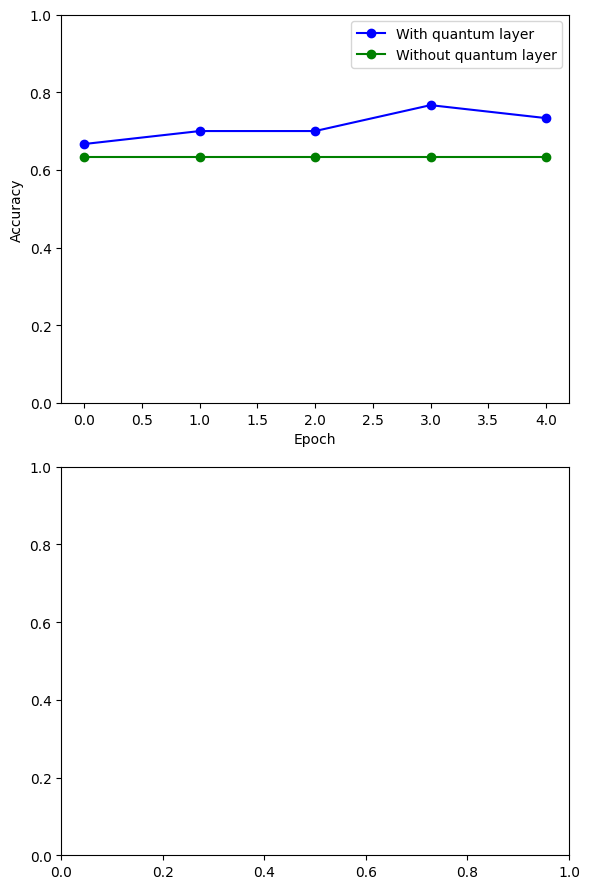

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 9))

ax1.plot(q_history.history["val_accuracy"], "-ob", label="With quantum layer")
ax1.plot(c_history.history["val_accuracy"], "-og", label="Without quantum layer")
ax1.set_ylabel("Accuracy")
ax1.set_ylim([0, 1])
ax1.set_xlabel("Epoch")
ax1.legend()

plt.tight_layout()
plt.show()